# Analyse du data drift — production contre entraînement (#17)

**Question** : les clients que le modèle score en production ressemblent-ils à ceux sur
lesquels il a été entraîné ? Sans cible en production (on ne sait pas encore qui fera
défaut), la dérive des **entrées** et des **scores** est le signal précoce disponible.

- **Référence** : échantillon stratifié de 20 000 lignes du train de P6 (dataset HF privé
  `WillIsback/credit-scoring-drift-reference`), avec le score du modèle servi.
- **Production** : appels réussis (`source = 'api'`, statut 200) de `prediction_logs`
  (Neon) sur la fenêtre analysée.
- **Calcul** : module partagé `credit_scoring.monitoring.drift` (Evidently 0.7.23), le même
  que le job planifié `drift-analysis` et que l'onglet Monitoring du Space.

Exécution (sous-projet `analysis/`, Evidently exige pandas < 3) :

```bash
DATABASE_URL=… HF_TOKEN=… uv run --project analysis jupyter nbconvert --execute --to notebook \
    --inplace notebooks/analyse_drift.ipynb
```

Ce notebook versionné ne montre **que des agrégats** (statistiques, histogrammes), jamais de
ligne client : les données Kaggle ne sont pas publiques.

In [1]:
import os
import warnings
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_scoring.model import load_model
from credit_scoring.monitoring import drift, metrics
from credit_scoring.monitoring.db import make_engine
from credit_scoring.monitoring.thresholds import THRESHOLDS

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

WINDOW = timedelta(days=int(os.environ.get("DRIFT_WINDOW_DAYS", "7")))
model = load_model(Path(os.environ.get("MODEL_DIR", ROOT / "artifacts")))
engine = make_engine(os.environ["DATABASE_URL"])

local_reference = os.environ.get("DRIFT_REFERENCE")
if local_reference:
    reference = pd.read_parquet(local_reference)
else:
    from huggingface_hub import hf_hub_download

    reference = pd.read_parquet(
        hf_hub_download(
            "WillIsback/credit-scoring-drift-reference", "reference.parquet", repo_type="dataset"
        )
    )
current = drift.production_frame(engine, WINDOW)
logs = metrics.load_logs(engine, WINDOW)
categorical = list(model.features.categories)
numerical = [c for c in model.features.input_features if c not in categorical]
print(f"Modèle : {model.version} · fenêtre : {WINDOW.days} jours")
print(f"Référence : {len(reference):,} lignes · production : {len(current):,} appels réussis")

Modèle : home-credit-serving v2 · fenêtre : 7 jours
Référence : 20,000 lignes · production : 1,374 appels réussis


## 1. Dérive feature par feature et dérive du score

In [2]:
result = drift.analyse(reference, current, numerical, categorical)
s = result.summary
features = pd.DataFrame(s["features"])
reports = ROOT / "reports"
reports.mkdir(exist_ok=True)
if result.html:
    (reports / "drift-report.html").write_text(result.html, encoding="utf-8")
print(
    f"Features en dérive : {s['n_drifted']} / {len(features)} ({s['share_drifted']:.1%})"
    f" — seuil d'alerte : {THRESHOLDS['drift_share_alert']:.0%}"
)
sd = s["score_drift"]
print(
    f"Score prob_default : {sd['method']} = {sd['stat']:.3f} (seuil {sd['threshold']}) →"
    f" {'dérive' if sd['drifted'] else 'stable'}"
)
print("Rapport Evidently interactif complet : reports/drift-report.html (non versionné)")
features.head(15).round(3)

Features en dérive : 17 / 122 (13.9%) — seuil d'alerte : 30%
Score prob_default : Wasserstein distance (normed) = 0.080 (seuil 0.1) → stable
Rapport Evidently interactif complet : reports/drift-report.html (non versionné)


,name,method,stat,threshold,drifted
0,autoFE_f_7,Wasserstein distance (normed),0.579,0.1,True
1,autoFE_f_1,Wasserstein distance (normed),0.555,0.1,True
2,autoFE_f_21,Wasserstein distance (normed),0.223,0.1,True
3,autoFE_f_82,Wasserstein distance (normed),0.216,0.1,True
4,autoFE_f_132,Wasserstein distance (normed),0.214,0.1,True
5,autoFE_f_131,Wasserstein distance (normed),0.206,0.1,True
6,autoFE_f_64,Wasserstein distance (normed),0.199,0.1,True
7,AMT_CREDIT,Wasserstein distance (normed),0.195,0.1,True
8,autoFE_f_43,Wasserstein distance (normed),0.193,0.1,True
9,PREV_CANCELED_COUNT,Wasserstein distance (normed),0.183,0.1,True


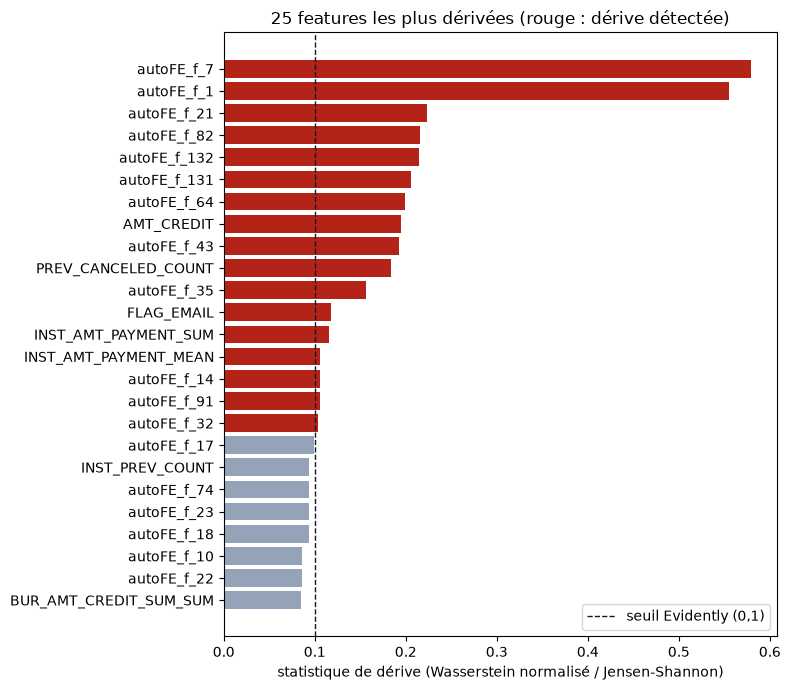

In [3]:
top = features.dropna(subset=["stat"]).head(25).iloc[::-1]
colors = ["#b42318" if d else "#94a3b8" for d in top["drifted"]]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top["name"], top["stat"], color=colors)
ax.axvline(0.1, color="#0f172a", ls="--", lw=1, label="seuil Evidently (0,1)")
ax.set_xlabel("statistique de dérive (Wasserstein normalisé / Jensen-Shannon)")
ax.set_title("25 features les plus dérivées (rouge : dérive détectée)")
ax.legend(loc="lower right")
plt.tight_layout()

### Lecture des familles de features

Les `autoFE_f_*` sont des combinaisons OpenFE de features brutes : elles amplifient la
dérive de leurs ingrédients. La part de dérive par famille dit si elle touche les
features lisibles ou seulement les combinaisons calculées.

In [4]:
features["famille"] = np.where(
    features["name"].str.startswith("autoFE_"), "autoFE (calculées)", "lisibles"
)
features.groupby("famille")["drifted"].agg(features="size", en_dérive="sum").assign(
    part=lambda t: (t["en_dérive"] / t["features"]).round(3)
)

,features,en_dérive,part
famille,,,
autoFE (calculées),79,12,0.152
lisibles,43,5,0.116


## 2. Distributions comparées

Les features les plus importantes pour le modèle (gain), `CODE_GENDER` (critère protégé,
ADR-007) et le score. Densités normalisées : chaque histogramme somme à 1.

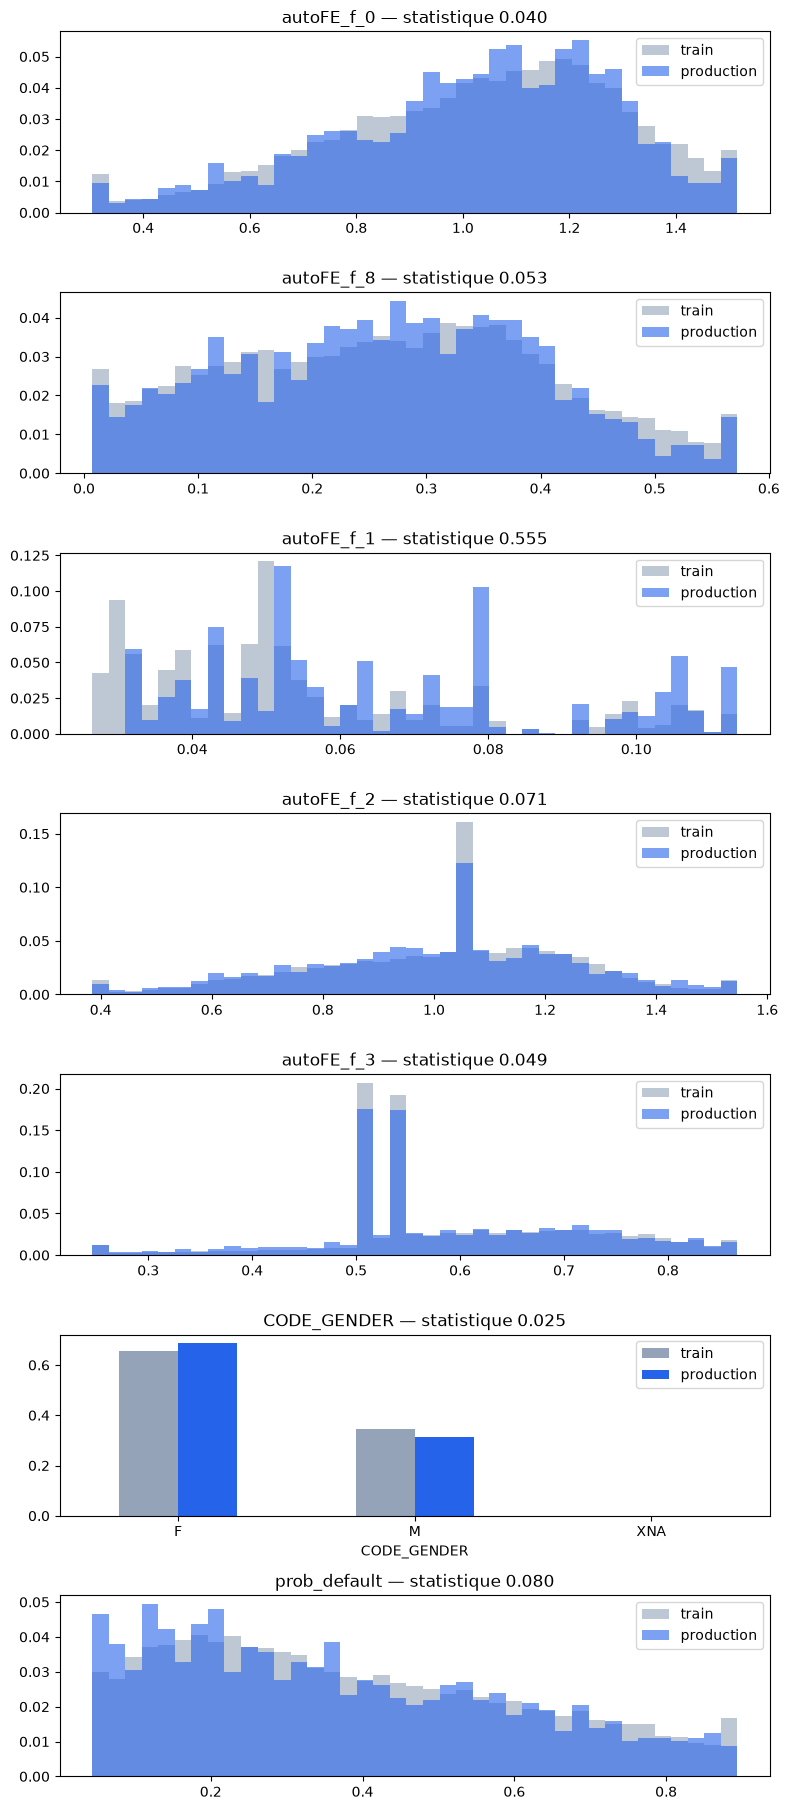

In [5]:
importance = sorted(model.importance.items(), key=lambda kv: kv[1][0])
key = [name for name, _ in importance[:5]]
shown = [*key, "CODE_GENDER", "prob_default"]
fig, axes = plt.subplots(len(shown), 1, figsize=(8, 2.6 * len(shown)))
for ax, col in zip(axes, shown, strict=True):
    if col in categorical:
        ref = reference[col].fillna("(absent)").value_counts(normalize=True)
        cur = current[col].fillna("(absent)").value_counts(normalize=True)
        both = pd.concat([ref.rename("train"), cur.rename("production")], axis=1).fillna(0)
        both.plot.bar(ax=ax, color=["#94a3b8", "#2563eb"], rot=0)
    else:
        lo, hi = np.nanpercentile(reference[col], [1, 99])
        bins = np.linspace(lo, hi, 40)
        for frame, label, color in (
            (reference, "train", "#94a3b8"),
            (current, "production", "#2563eb"),
        ):
            values = pd.to_numeric(frame[col], errors="coerce").dropna().clip(lo, hi)
            ax.hist(
                values,
                bins=bins,
                weights=np.full(len(values), 1 / max(len(values), 1)),
                alpha=0.6,
                label=label,
                color=color,
            )
    stat = features.set_index("name")["stat"].get(
        col, sd["stat"] if col == "prob_default" else None
    )
    ax.set_title(f"{col} — statistique {stat:.3f}" if stat is not None else col)
    ax.legend()
plt.tight_layout()

## 3. Valeurs manquantes : la piste `bureau_balance` de P6

En P6, la table `bureau_balance` couvrait 30 % des clients du train contre 87 % du test :
ses agrégats (`BUR_MONTHS_MEAN`, `BUR_LATE_RATIO_*`, `BUR_DPD_LEVEL_MAX`) étaient à
surveiller en priorité. Aucun n'a été retenu par la sélection de features du modèle : seules
des features de `bureau` (`BUR_*`) restent, et `bureau_balance` ne peut agir qu'à travers
des combinaisons OpenFE. Le taux de valeurs manquantes compare les deux populations : des taux
nuls des deux côtés signifient que P6 a imputé ces valeurs en amont, et l'écart de couverture
ne se lit alors que dans les distributions (section 2).

In [6]:
bur = [c for c in model.features.input_features if c.startswith("BUR_")]
missing = pd.DataFrame(
    {
        "train": reference[bur].isna().mean(),
        "production": current.reindex(columns=bur).isna().mean(),
    }
)
missing["écart"] = missing["production"] - missing["train"]
missing.round(3)

,train,production,écart
BUR_DAYS_CREDIT_MIN,0.0,0.0,0.0
BUR_AMT_CREDIT_SUM_SUM,0.0,0.0,0.0
BUR_DEBT_CREDIT_RATIO_MEAN,0.0,0.0,0.0
BUR_ACT_DAYS_CREDIT_MEAN,0.0,0.0,0.0


## 4. Anomalies opérationnelles (même fenêtre, trafic de production)

In [7]:
ops = metrics.summary(logs)
pd.Series(
    {
        "appels": ops["n"],
        "taux d'acceptation": ops["acceptance_rate"],
        "taux d'erreur": ops["error_rate"],
        "latence p50 (ms)": ops["latency_p50"],
        "latence p95 (ms)": ops["latency_p95"],
        "inférence p95 (ms)": ops["inference_p95"],
    }
).round(3)

appels                1500.000
taux d'acceptation       0.745
taux d'erreur            0.084
latence p50 (ms)        14.762
latence p95 (ms)        15.796
inférence p95 (ms)      13.077
dtype: float64

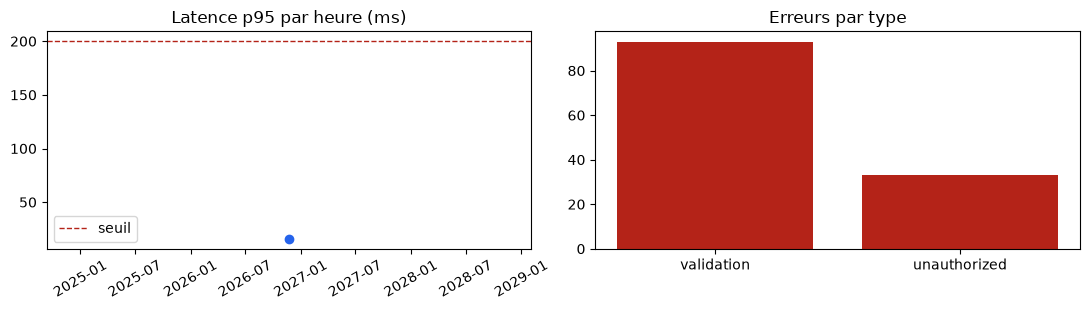

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2))
hourly = metrics.hourly(logs)
a1.plot(hourly["hour"], hourly["latency_p95"], marker="o", color="#2563eb")
a1.axhline(THRESHOLDS["latency_p95_ms_alert"], color="#b42318", ls="--", lw=1, label="seuil")
a1.set_title("Latence p95 par heure (ms)")
a1.legend()
a1.tick_params(axis="x", rotation=30)
errors = metrics.errors_by_type(logs)
a2.bar(errors["error_type"], errors["count"], color="#b42318")
a2.set_title("Erreurs par type")
plt.tight_layout()

## 5. Interprétation (👤 William)

*À rédiger par William, comme en soutenance.* Points à traiter :

- Part de features en dérive et familles touchées : est-ce grave ? Une dérive des entrées
  ne dit pas que les décisions sont fausses (pas de cible en production) : que dit la
  **dérive du score**, et que dit le taux d'acceptation ?
- Taille de fenêtre : avec quelques centaines d'appels, une statistique de Wasserstein
  dépasse 0,1 par simple bruit d'échantillonnage (constaté pendant les tests du module).
- Population de production : les clients simulés viennent du **jeu de test** Kaggle,
  qui diffère du train (piste `bureau_balance`, section 3).
- `CODE_GENDER` : la répartition par sexe a-t-elle bougé ?

## 6. Seuils d'alerte et action (👤 William)

*À fixer par William* dans `src/credit_scoring/monitoring/thresholds.py` (valeurs actuelles
ci-dessous, proposées par l'agent), avec l'action associée à chaque seuil : surveiller,
ajuster (seuil métier), réentraîner.

In [9]:
pd.Series(THRESHOLDS)

drift_share_alert         0.30
score_drift_alert         0.10
error_rate_alert          0.05
latency_p95_ms_alert    200.00
dtype: float64